In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
X = panel[FEATURES].fillna(panel[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

In [3]:
panel["cluster"] = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(X_scaled)
print(panel["cluster"].value_counts().sort_index())
print(f"noise: {(panel['cluster'] == -1).mean():.1%}")

cluster
-1    133
 0     51
 1     50
 2     21
 3     47
 4     28
 5     77
 6     21
 7     29
Name: count, dtype: int64
noise: 29.1%


HDBSCAN creates 8 density-based clusters on 11 scaled features based on closeness in feature space. Each day gets a cluster label, or -1 (noise) if it doesn't fit any dense group.

A cluster needs at least 15 similar days to form a cluster (`min_cluster_size=15`), and each day is judged using its 5 nearest neighbours (`min_samples=15`).

### PCA plot coloured by cluster

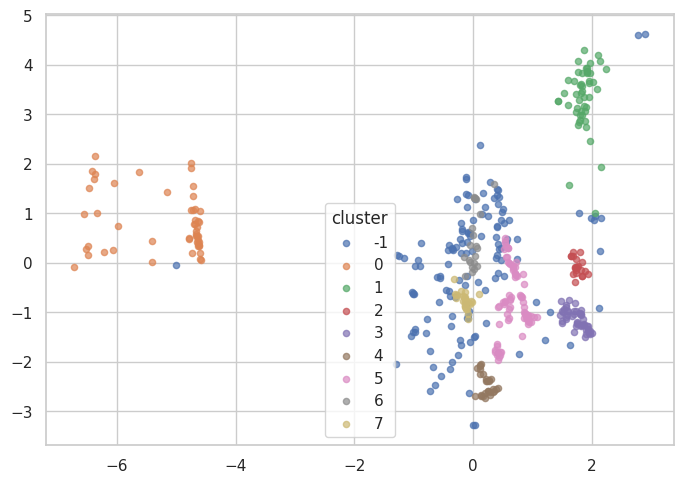

In [4]:
pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]

plt.figure(figsize=(7, 5))
for c in sorted(panel["cluster"].unique()):
    s = panel[panel["cluster"] == c]
    plt.scatter(s["x"], s["y"], label=c, alpha=0.7, s=20)
plt.legend(title="cluster")
plt.tight_layout()
plt.show()

- Cluster -1 (noise) is scattered around the middle & days in this cluster sit between groups or on the edges.
- Cluster 0 distinctively indicates low leverage and high distance_to_liq on the far left. Well separated from the looping whales.
- Cluster 1 sits at the top right with very high ltv, loop_depth, and carry_spread_levered - max leverage, well clear of the main cloud.
- Clusters 2 & 3 share the same high-leverage position on the right; cluster 2 sits on the upper band (fresher, ~1 month since rebalance) and cluster 3 on the lower band (staler, ~2.5 months) with no overlap between them.
- Cluster 4 sits at the bottom of the plot with high ltv but negative carry_spread - underwater on carry separate from the main looping group.
- Cluster 5 forms the largest block centre-right — typical active loop (ltv ~90%, moderate loop_depth) and the main bulk of the cloud.
- Cluster 6 sits in the centre, slightly above cluster 5 — same broad high-leverage region but with more frequent rebalancing (rebal_freq_7d).
- Cluster 7 sits left of centre with lower ltv and shallower loop_depth — more conservative looping, more buffer via distance_to_liq.


### PCA plot coloured by `whale_id`

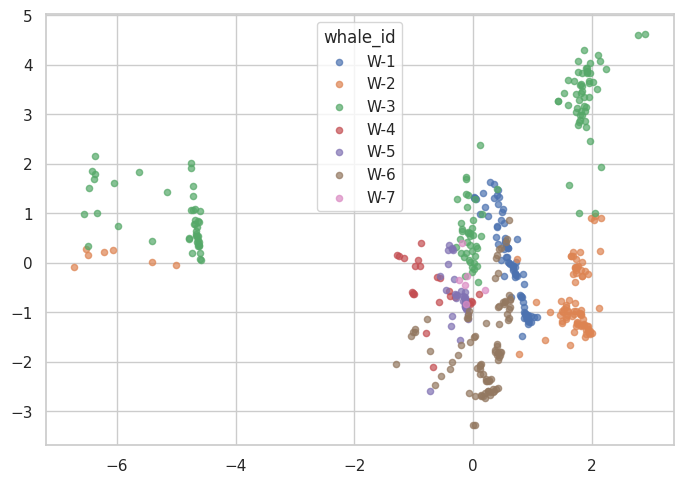

In [5]:
plt.figure(figsize=(7, 5))
for w in sorted(panel["whale_id"].unique()):
    s = panel[panel["whale_id"] == w]
    plt.scatter(s["x"], s["y"], label=w, alpha=0.7, s=20)
plt.legend(title="whale_id")
plt.tight_layout()
plt.show()

This plot shows where each whale’s days sit in the same PCA space, so you can see how they spread across leverage and rebalancing or carry.

Whales with noise days: W-6, W-3, W-1, W-4, W-2, W-5 & W-7 (W-7 is all noise with only 6 days).

W-3 is the most versatile & spans the widest area: far left when unwound, top right at max leverage, & centre when actively rebalancing.

Most other whales sit in tighter patches, which is why baseline clustering often lines up with who is trading rather than a shared strategy type.

In [6]:
panel.groupby("cluster")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster,,,,,,,,,,,
-1,0.864,8.940,0.069,0.011,0.022,1.594,5.286,8.368,0.879,2.324,22.816
0,0.000,0.000,0.965,0.099,0.142,2.314,8.490,2.000,0.229,2.877,0.000
1,0.959,24.120,0.006,0.000,0.001,4.980,17.360,0.400,0.959,3.683,88.855
2,0.935,15.524,0.030,0.000,0.000,0.000,0.286,34.476,0.935,5.510,85.457
3,0.936,15.766,0.029,0.000,0.000,0.000,0.000,72.213,0.936,3.897,61.451
4,0.890,9.000,0.030,0.001,0.001,0.000,0.000,54.821,0.890,-0.622,-5.600
5,0.904,10.403,0.013,0.001,0.002,0.143,3.065,25.818,0.904,3.029,31.900
6,0.870,7.714,0.080,0.004,0.004,2.238,7.381,2.333,0.877,3.265,25.182
7,0.820,5.241,0.095,0.000,0.004,0.034,2.897,16.690,0.820,3.914,20.412


Untuned HDBSCAN does find interpretabel risk states (flap, max loop, stale, negative carry, active rebal, etc) but:
- there are too many clusters (8 + noise) for clean archetypes.
- ~29% of days belong to the cluster -1 (noise).
- Several are 100% one whale.

The next notebook should balance whales, tune `min_cluster_size`, and assign centriod so we get 3-4 cross-whale archetypes. 